In [1]:
import sys
import utils_exp_1 as utils
from importlib import reload
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
reload(utils)
from tqdm import tqdm
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import plotting_exp as plt_AMM

C:\Users\muham\AppData\Roaming\Python\Python38\site-packages\pandas\core\computation\expressions.py:20: UserWarning: Pandas requires version '2.7.3' or newer of 'numexpr' (version '2.7.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
import matplotlib.pylab as pylab
params = {'legend.fontsize': 'x-large',
          'figure.figsize': (8, 5),
         'axes.labelsize': 'x-large',
         'axes.titlesize':'x-large',
         'xtick.labelsize':'x-large',
         'ytick.labelsize':'x-large'}
pylab.rcParams.update(params)
%config InlineBackend.figure_format = "retina"

import matplotlib
plt.rc('text', usetex=True)
plt.rc('text.latex', preamble=r'\usepackage{amsmath,amsfonts}')
dpi = 300

In [5]:
Nt = 10_000
S0 = 2820.
Z0 = S0
T = 1.
sigma_Binance = 0.0569 * S0  # we obtained this from market-milk daily volatility accessed 18 Dec 2024
tr_cost = 2e-7   # 10/100*0.01 * S0  # 10 bps

xi = 875 #567 for median or 875.0 for mean
fee = (100/100*0.01 * Z0) * xi 
a1= 142.712
a3= 13.568

kappaSQ = 316477600787601.7 * 10
Y0 = np.sqrt(kappaSQ / Z0)
eta = 50_000 #25589 * 3#1e4 #25589 * 3

risk_type = 'averse-small'

In [6]:
params_env = {'sigma': sigma_Binance, 'S0': S0, 'Z0': Z0, 
              'Y0': Y0, 
              'eta': eta, 
              'xi': xi, 'T': T, 'a1': a1, 'a2': 1e-7, 'a3': a3, 'Nt': Nt,
              'fee': 0., 'feeV': fee, 'C': 0., 'gamma': 1e-10, 'zeta': 5e-12, 'tempLP': tr_cost, 'P0': 1} # gamma was 1e-8

In [7]:
env = utils.environment(**params_env)

In [8]:
mins_per_step = 24*60/10_000

In [9]:
np.random.seed(100)

nsims = 1_000
strag_LP = '1'
strag_vn = 'exp'

S, Y, Z, X, nu, wealth, perf, rew, venue_wealth, A_a_hist, A_b_hist, A_W_hist, A_B_hist, rew_drift_hist, _ = env.simulate_venue(nsims=nsims, strag_LP=strag_LP, strag_vn=strag_vn, verbose = True)

In [10]:
mins_per_step = 24*60/10_000
Nwindow = int(10/mins_per_step)

df = pd.DataFrame(data=np.concatenate((S.ravel().reshape(-1,1),Z.ravel().reshape(-1,1)),axis=1), columns=('S','Z'))
df['difference'] = df['S'] - df['Z']
diffs = df['difference'].rolling(Nwindow).mean()
diffs.dropna(inplace=True)

In [11]:
keepNumber = int(24*60/10)
diffs = diffs.iloc[::keepNumber]

In [12]:
fs = 14
fsL = 19
plt.rcParams["font.size"] = fs

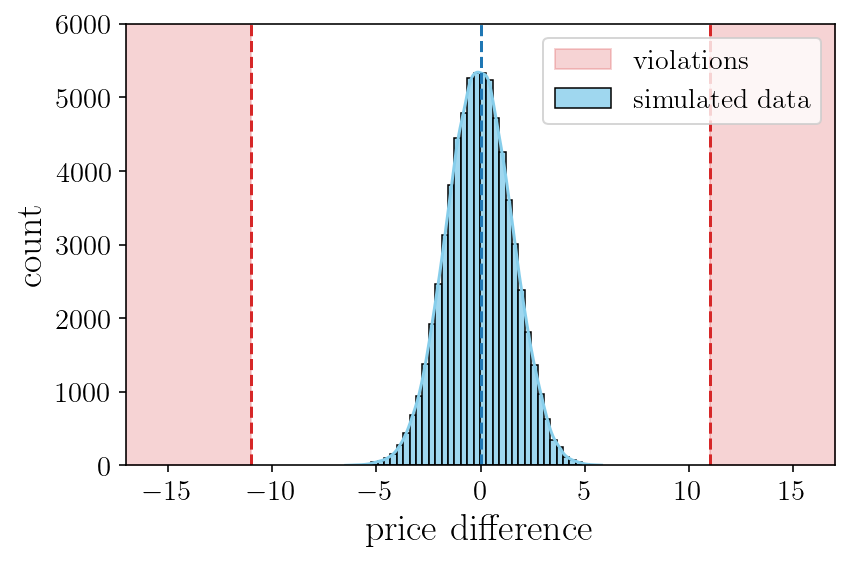

In [13]:
import seaborn as sns
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,4))

x = -10.994492750981774

sns.histplot(data=diffs, bins=40, kde=True, color="skyblue", label = r'$\mathrm{simulated}$ $\mathrm{data}$', ax=axs, alpha =0.8)
axs.set_xlabel(r'$\mathrm{price\,\,difference}$', fontsize = fsL)
axs.set_ylabel(r'$\mathrm{count}$', fontsize = fsL)

axs.axvline(0,linestyle = '--', color='tab:blue')
axs.axvline(x,linestyle = '--', color='tab:red')
axs.axvline(-x,linestyle = '--', color='tab:red')

xmin = -17
xmax = 17
ymax = 6_000

xaux_left = np.linspace(xmin, x, 100)
xaux_right = np.linspace(-x, xmax, 100)

axs.fill_between(xaux_left, ymax*np.ones_like(xaux_left), color = 'tab:red' , alpha=0.2, label= r'$\mathrm{violations}$')
axs.fill_between(xaux_right, ymax*np.ones_like(xaux_right), color = 'tab:red' , alpha=0.2)

plt.ylim([0,ymax])
plt.tight_layout()
plt.xlim([xmin,xmax])
plt.legend(fontsize=fs)

plt.tight_layout()
plt.savefig(f'figures/negative-intensity-regions-symm-simulations-{risk_type}.pdf', format="pdf", dpi=dpi)
plt.show()

In [14]:
qtl_Y = np.zeros((len(env.timesteps),3))
qtl_nu = np.zeros((len(env.timesteps),3))
qtl_rew = np.zeros((len(env.timesteps),3))
qtl_Z = np.zeros((len(env.timesteps),3))
qtl_S = np.zeros((len(env.timesteps),3))

for it, t in enumerate(env.timesteps):
    qtl_Y[it, :] = np.quantile(Y[it,:],[0.05,0.5,0.95],axis=0)
    qtl_nu[it, :] = np.quantile(nu[it,:],[0.05,0.5,0.95],axis=0)
    qtl_rew[it, :] = np.quantile(rew[it,:],[0.05,0.5,0.95],axis=0)
    qtl_Z[it, :] = np.quantile(Z[it,:],[0.05,0.5,0.95],axis=0)
    qtl_S[it, :] = np.quantile(S[it,:],[0.05,0.5,0.95],axis=0)

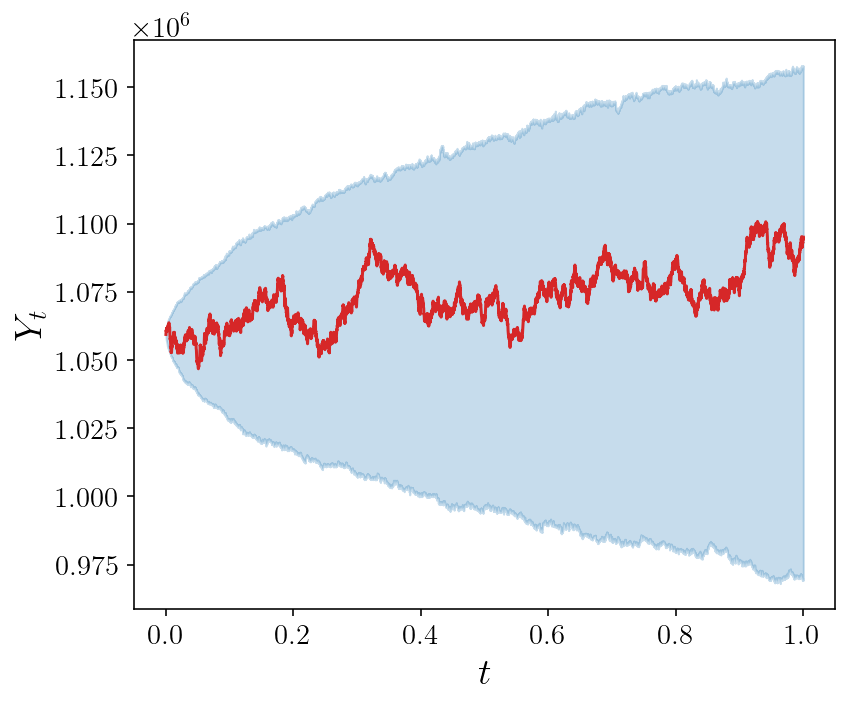

In [15]:
nsim = 53

fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,5))
plt.plot(env.timesteps, Y[:,nsim], label=r'$Y$', color ='tab:red')
plt.fill_between(env.timesteps,qtl_Y[:,0],qtl_Y[:,-1], color='tab:blue', alpha=0.25)
plt.xlabel(r'$t$', fontsize = fsL)
plt.ylabel(r'$Y_t$', fontsize = fsL)
plt.tight_layout()
plt.savefig(f'figures/baseline-sim-Y-paths-{risk_type}.pdf', format="pdf", dpi=dpi)
plt.show()

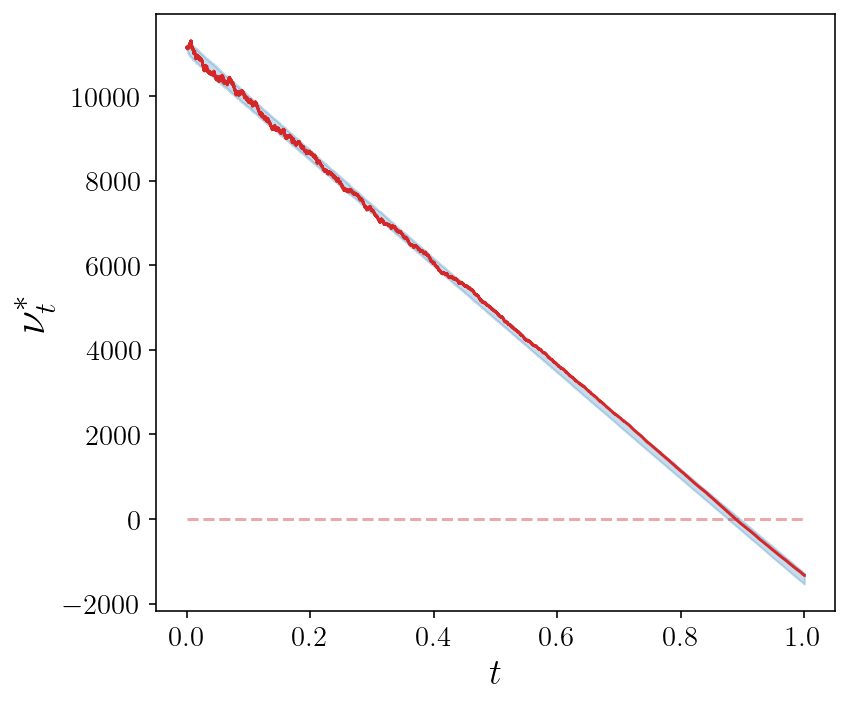

In [16]:
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,5))
plt.plot(env.timesteps, nu[:,nsim], label=r'$\nu$', color ='tab:red')
plt.fill_between(env.timesteps,qtl_nu[:,0],qtl_nu[:,-1], color='tab:blue', alpha=0.25)
plt.xlabel(r'$t$', fontsize = 18)
plt.ylabel(r'$\nu^*_t$', fontsize = 22)
plt.hlines(y = 0, xmin = 0, xmax = 1, linestyle = '--', alpha = 0.4, color='tab:red')
plt.tight_layout()
plt.savefig(f'figures/baseline-sim-nu-paths-{risk_type}.pdf', format="pdf", dpi=dpi)
plt.show()

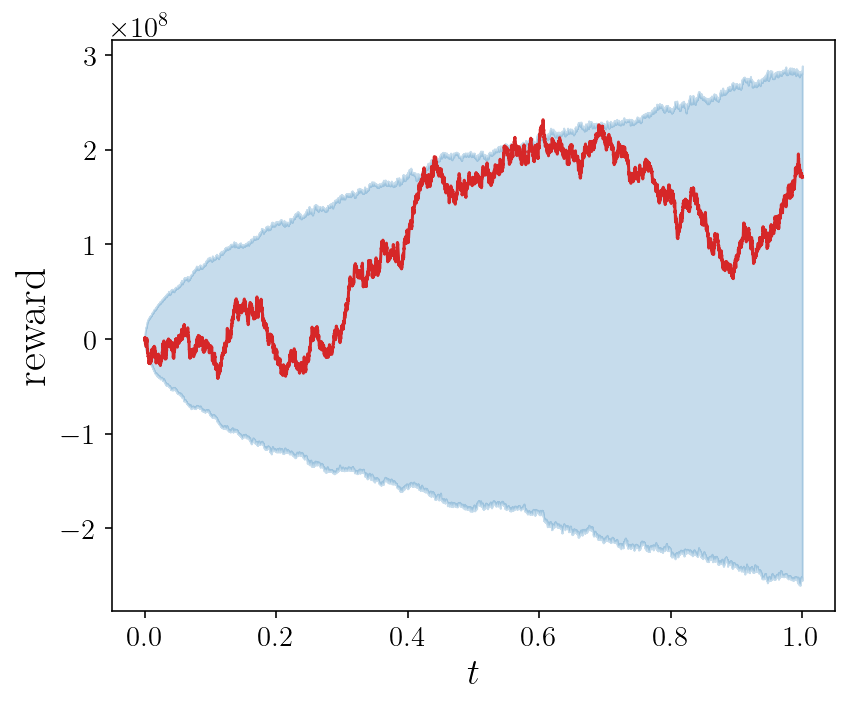

In [17]:
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,5))
plt.plot(env.timesteps, rew[:,nsim], label='reward', color ='tab:red')
plt.fill_between(env.timesteps,qtl_rew[:,0],qtl_rew[:,-1], color='tab:blue', alpha=0.25)
plt.xlabel(r'$t$', fontsize = 18)
plt.ylabel(r'$\mathrm{reward}$', fontsize = 22)
plt.tight_layout()
plt.savefig(f'figures/baseline-sim-rew-paths-{risk_type}.pdf', format="pdf", dpi=dpi)
plt.show()

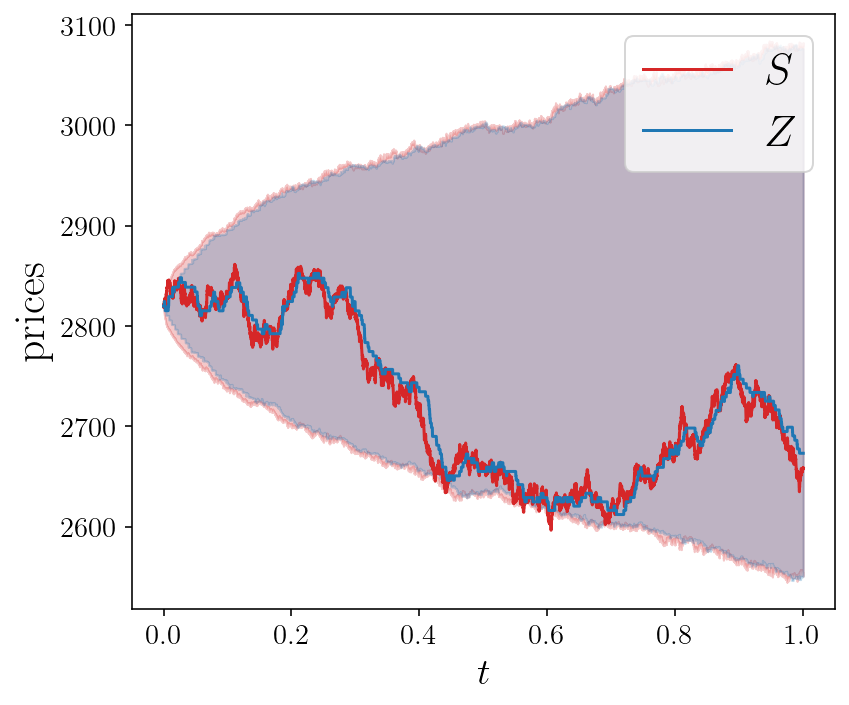

In [18]:
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,5))
plt.plot(env.timesteps, S[:,nsim], label=r'$S$', color ='tab:red')
plt.plot(env.timesteps, Z[:,nsim], label=r'$Z$', color ='tab:blue')

plt.fill_between(env.timesteps,qtl_S[:,0],qtl_S[:,-1], color='tab:red', alpha=0.25)
plt.fill_between(env.timesteps,qtl_Z[:,0],qtl_Z[:,-1], color='tab:blue', alpha=0.25)

plt.xlabel(r'$t$', fontsize = fsL)
plt.ylabel(r'$\mathrm{prices}$', fontsize = fsL+3)
plt.legend(fontsize = fsL+3)
plt.tight_layout()
plt.savefig(f'figures/baseline-sim-S-Z-paths-{risk_type}.pdf', format="pdf", dpi=dpi)
plt.show()

In [19]:
reload(plt_AMM)

<module 'plotting_exp' from 'D:\\(Akademik)\\(CDT in Mathematics of Random Systems)\\[AMM Implementation]\\plotting_exp.py'>

When tempLP = 3.2e-06  and gamma =1.6e-09 we should start negative


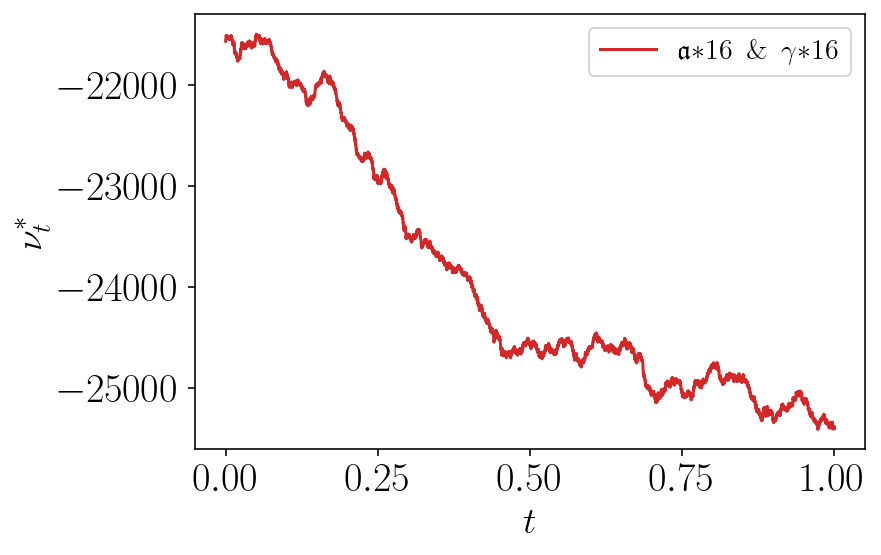

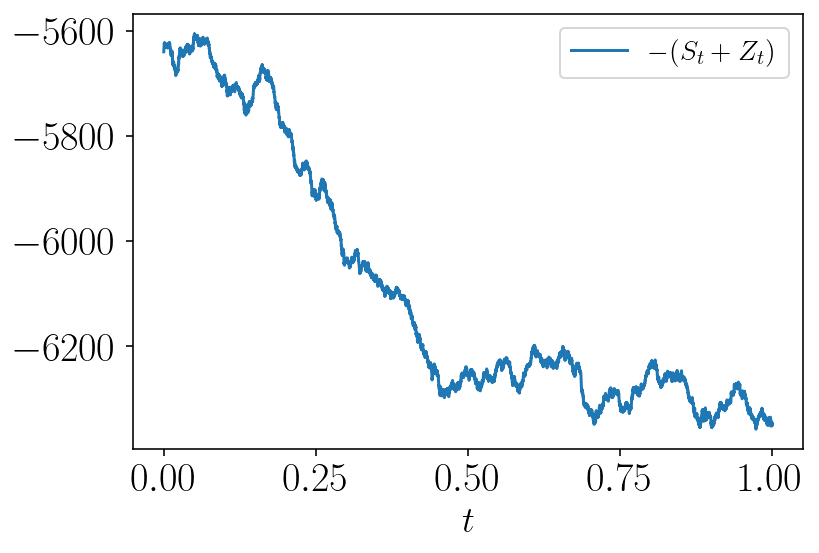

In [20]:
values = [16]
plt_AMM.stress_two_parameters_two_sets_and_show_nu('tempLP', 'gamma', values1 = values, values2 = values , params=params_env,
                                                   to_print1 =r'$\mathfrak{a}$', to_print2 = r'$\gamma$', showZero = False, showSZ = True, nsim = nsim)

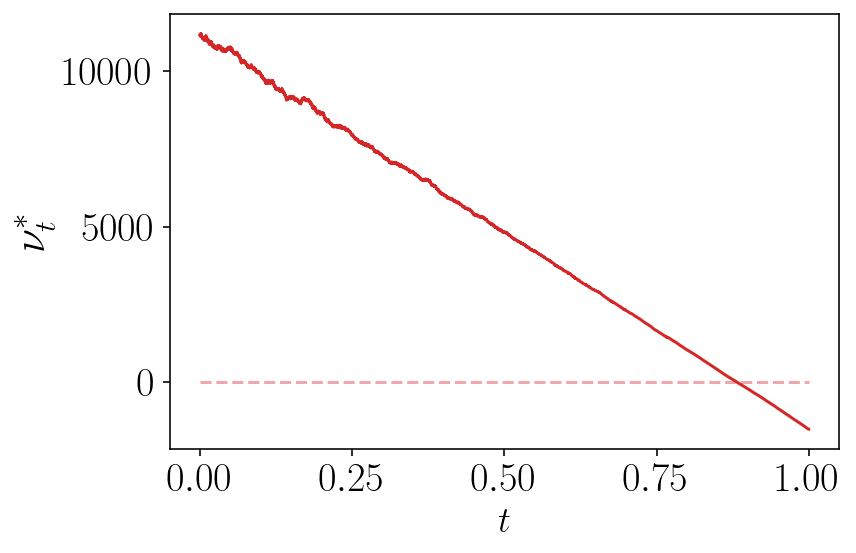

In [21]:
plt_AMM.params_show_nu(params_env)

In [22]:
values = [1,2,4,8,16]
colors = ['tab:red', 'tab:orange', 'skyblue', 'tab:green', 'tab:blue']

When eta = 12500.0  and tempLP =8e-07 we should start positive
When eta = 25000.0  and tempLP =4e-07 we should start positive
When eta = 50000.0  and tempLP =2e-07 we should start positive
When eta = 100000.0  and tempLP =1e-07 we should start positive
When eta = 200000.0  and tempLP =5e-08 we should start positive


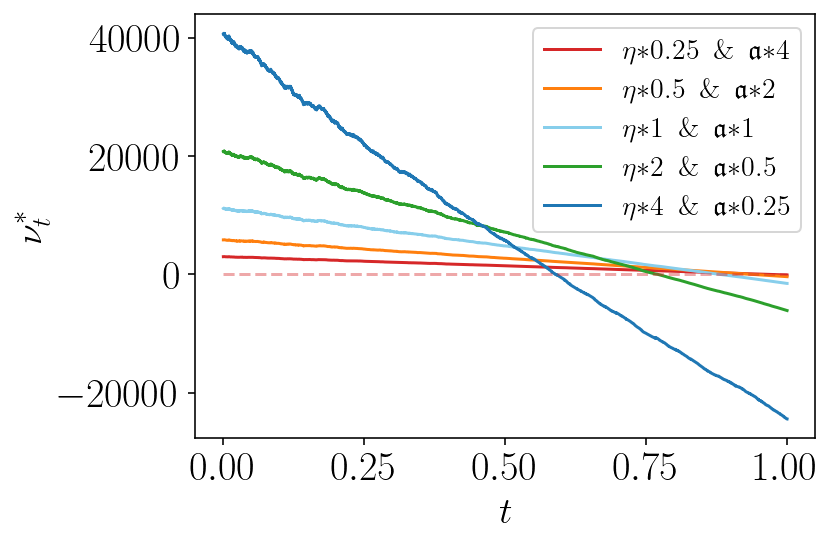

In [23]:
values1 = [1/4, 1/2, 1,2,4]
values2 = [4,2, 1,1/2,1/4]
plt_AMM.stress_two_parameters_two_sets_and_show_nu(parameter1 = 'eta', parameter2 ='tempLP', values1 = values1, values2 = values2, params = params_env,
                                                   to_print1 =r'$\eta$', to_print2 = r'$\mathfrak{a}$', logScale = False, colors = colors,
                                                  savefig = True, filename = f'stress-eta-tempLP-{risk_type}')

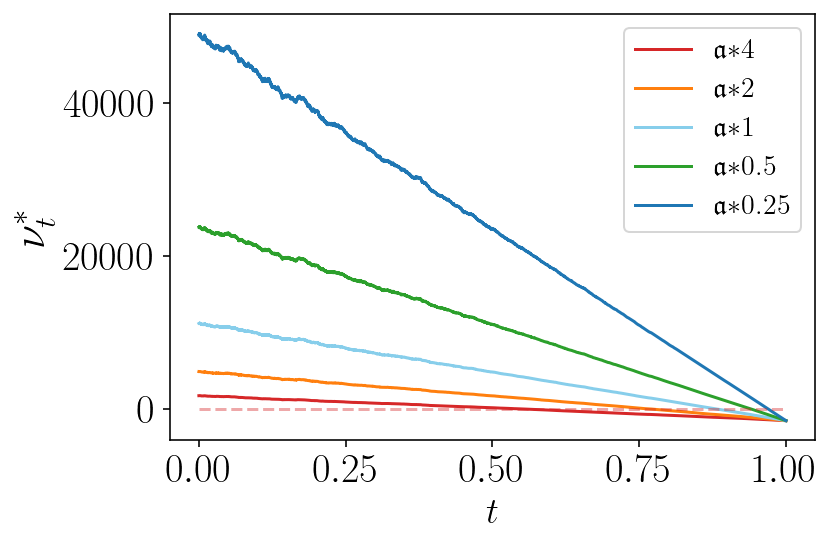

In [24]:
plt_AMM.stress_parameter_and_show_nu('tempLP', values=values2,  params=params_env, 
                                     savefig = True, filename = f'stress-tempLP-{risk_type}', to_print=r'$\mathfrak{a}$')

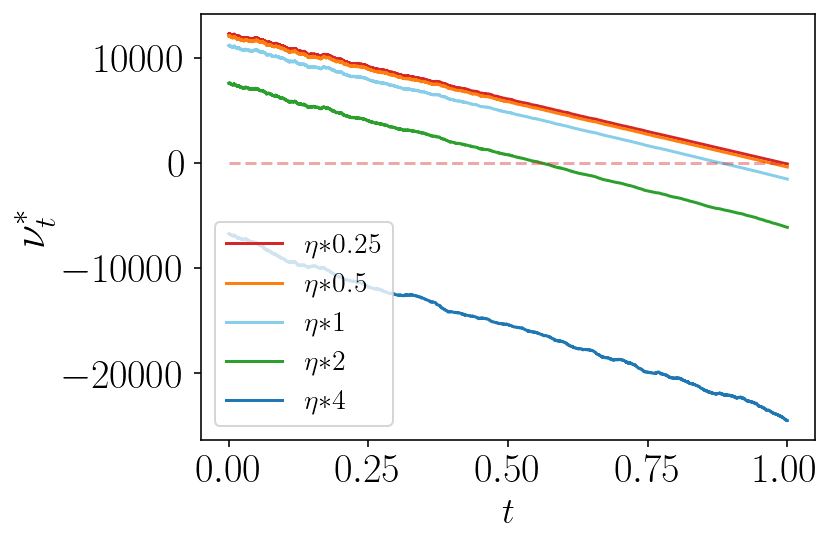

In [25]:
plt_AMM.stress_parameter_and_show_nu('eta', values = values1, params=params_env, to_print=r'$\eta$',
                                     savefig = True, filename = f'stress-eta-{risk_type}')

When feeV = 24675.0  and tempLP =1.6e-06 we should start positive
When feeV = 49350.0  and tempLP =8e-07 we should start positive
When feeV = 98700.0  and tempLP =4e-07 we should start positive
When feeV = 197400.0  and tempLP =2e-07 we should start positive


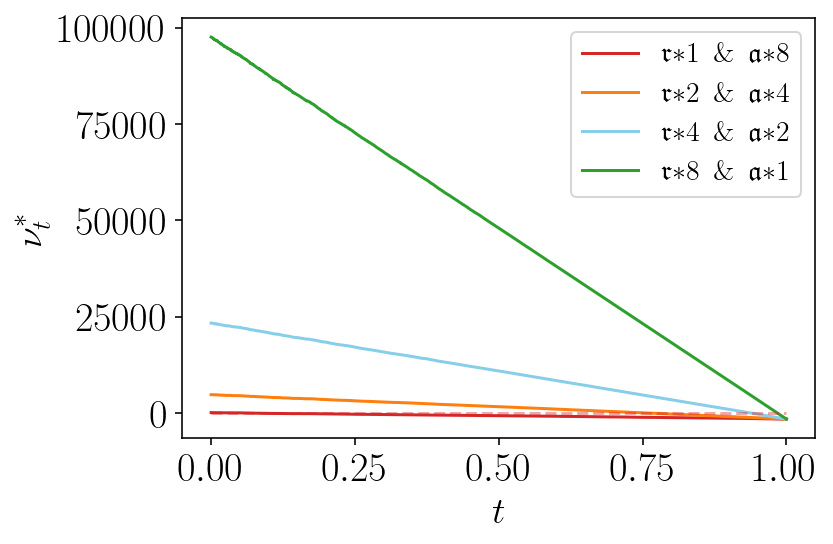

In [26]:
values1 = [1,2,4,8]
values2 = [8,4,2,1]
plt_AMM.stress_two_parameters_two_sets_and_show_nu('feeV', 'tempLP', values1 = values1, values2 = values2, params=params_env,
                                                   to_print1 ='$\mathfrak{r}$', to_print2 = r'$\mathfrak{a}$', logScale = False, 
                                                  savefig = True, filename = f'stress-feeV-tempLP-{risk_type}')

When feeV = 24675.0  and xi =875 we should start positive
When feeV = 49350.0  and xi =1750 we should start positive
When feeV = 98700.0  and xi =3500 we should start positive
When feeV = 197400.0  and xi =7000 we should start positive
When feeV = 394800.0  and xi =14000 we should start positive


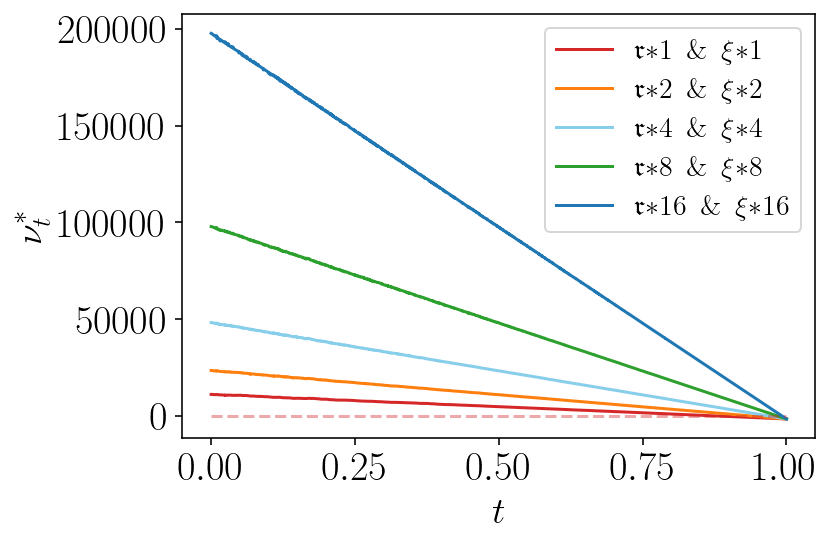

In [27]:
plt_AMM.stress_two_parameters_two_sets_and_show_nu('feeV', 'xi', values1 = values, values2 = values, params=params_env,
                                                   to_print1 ='$\mathfrak{r}$', to_print2 = r'$\xi$',
                                                  savefig = True, filename = f'stress-feeV-xi-{risk_type}')

When feeV = 6168.75  and gamma =4e-10 we should start negative
When feeV = 12337.5  and gamma =2e-10 we should start positive
When feeV = 24675.0  and gamma =1e-10 we should start positive
When feeV = 49350.0  and gamma =5e-11 we should start positive
When feeV = 98700.0  and gamma =2.5e-11 we should start positive


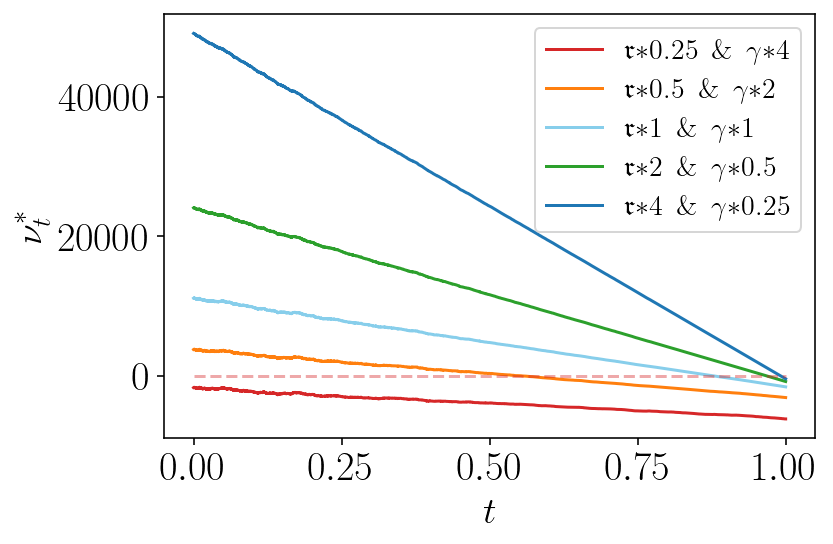

In [28]:
values1 = [1/4, 1/2, 1,2,4]
values2 = [4,2, 1,1/2,1/4]
plt_AMM.stress_two_parameters_two_sets_and_show_nu('feeV', 'gamma', values1 = values1, values2 = values2, params=params_env,
                                                   to_print1 =r'$\mathfrak{r}$', to_print2 = r'$\gamma$',
                                                  savefig = True, filename = f'stress-feeV-gamma-{risk_type}')

When tempLP = 2e-07  and gamma =1e-10 we should start positive
When tempLP = 4e-07  and gamma =2e-10 we should start positive
When tempLP = 8e-07  and gamma =4e-10 we should start negative
When tempLP = 1.6e-06  and gamma =8e-10 we should start negative
When tempLP = 3.2e-06  and gamma =1.6e-09 we should start negative


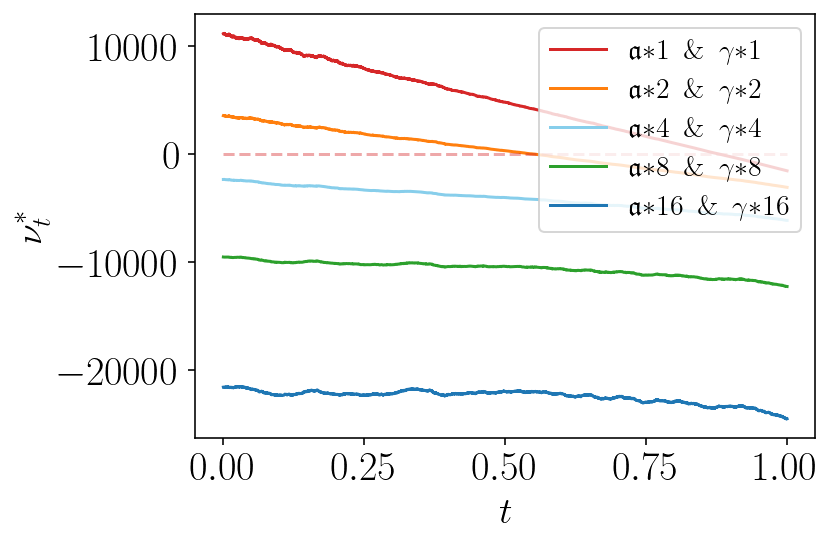

In [29]:
plt_AMM.stress_two_parameters_two_sets_and_show_nu('tempLP', 'gamma', values1 = values, values2 = values, params=params_env,
                                                   to_print1 =r'$\mathfrak{a}$', to_print2 = r'$\gamma$',
                                                  savefig = True, filename = f'stress-tempLP-gamma-{risk_type}')

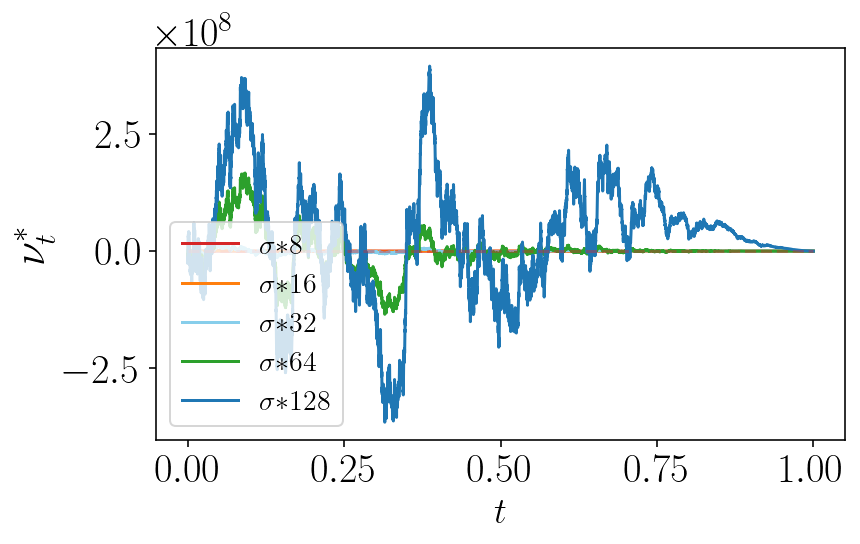

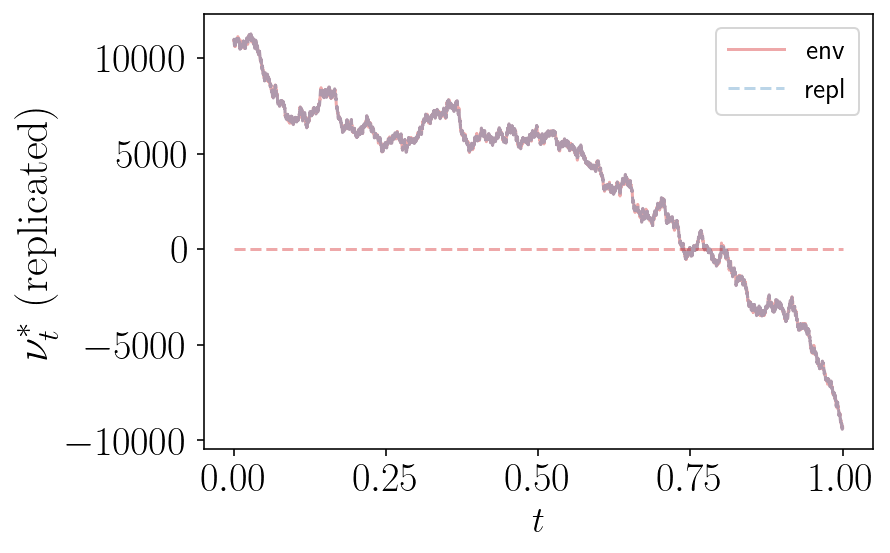

In [30]:
plt_AMM.stress_parameter_and_show_nu('sigma', values = [8,16,32,64,128], to_print=r'$\sigma$', params=params_env,
                                    savefig = True, filename = f'stress-sigma-{risk_type}', verbose = True)

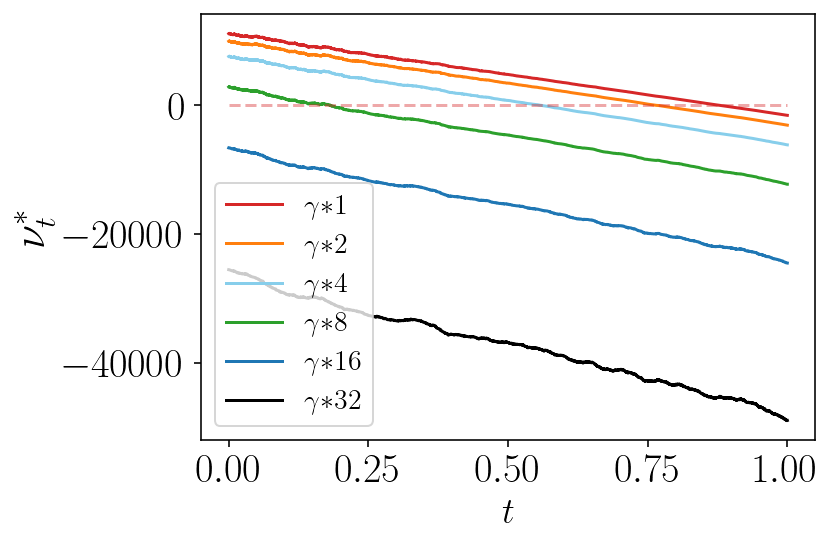

In [31]:
plt_AMM.stress_parameter_and_show_nu('gamma', values = [1,2,4,8,16,32],params=params_env, to_print=r'$\gamma$',
                                     savefig = True, filename = f'stress-gamma-{risk_type}')

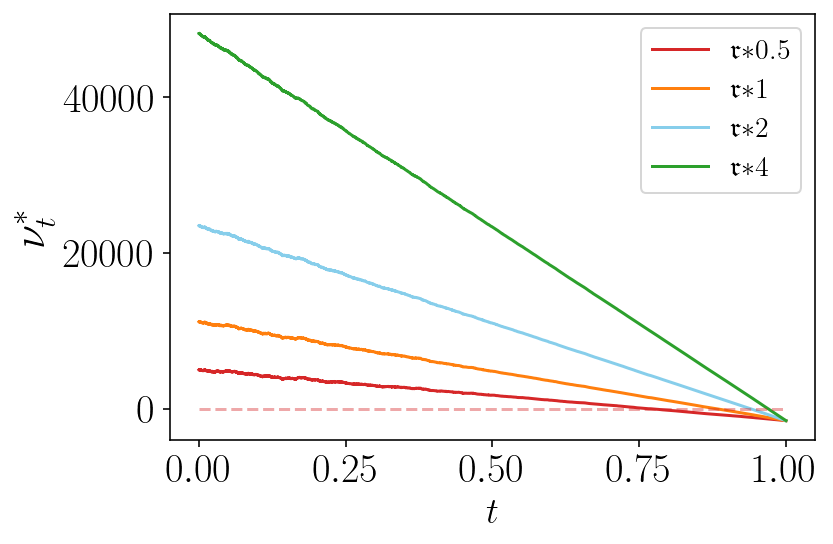

In [32]:
plt_AMM.stress_parameter_and_show_nu('feeV', values = [0.5,1,2,4], params=params_env, to_print=r'$\mathfrak{r}$',
                                     savefig = True, filename = f'stress-feeV-{risk_type}')

In [33]:
nsims = 10_000
strag_LP = '1'
strag_vn = '1'
S, Y, Z, X, nu, wealth, perf, rew, venue_wealth, A_a_hist, A_b_hist, A_W_hist, A_B_hist, rew_drift_hist, _ = env.simulate_venue(nsims=nsims, strag_LP=strag_LP, strag_vn=strag_vn, verbose = True)

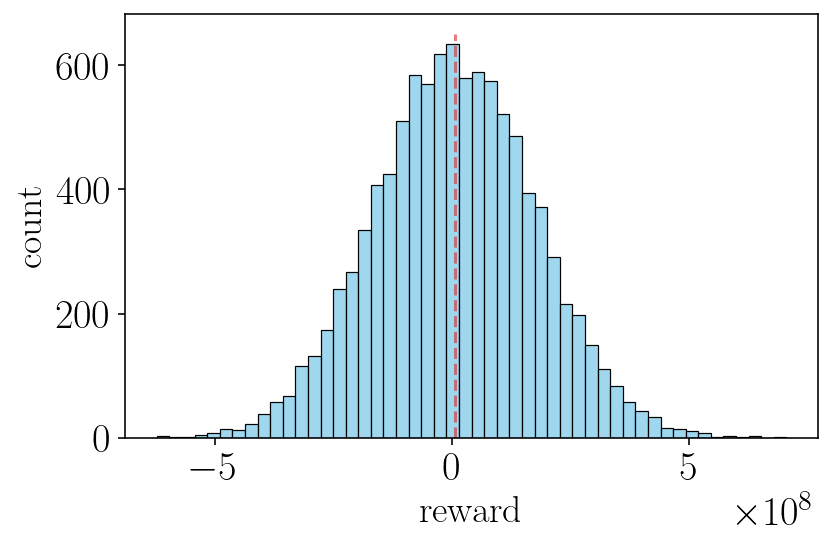

In [34]:
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,4))

sns.histplot(data=rew[-1,:], bins = 50, kde=False, color="skyblue",  ax=axs, alpha =0.8)
plt.vlines(x = np.mean(rew[-1,:]), ymin=0,ymax=650, linestyle='--', color='tab:red', alpha =0.6)
axs.set_xlabel(r'$\mathrm{reward}$', fontsize = fsL)
axs.set_ylabel(r'$\mathrm{count}$', fontsize = fsL)
plt.tight_layout()
plt.savefig(f'figures/hist-sim-rews-{risk_type}.pdf', format="pdf", dpi=dpi)
plt.show()

In [35]:
np.mean(rew[-1,:])

6003497.45591617

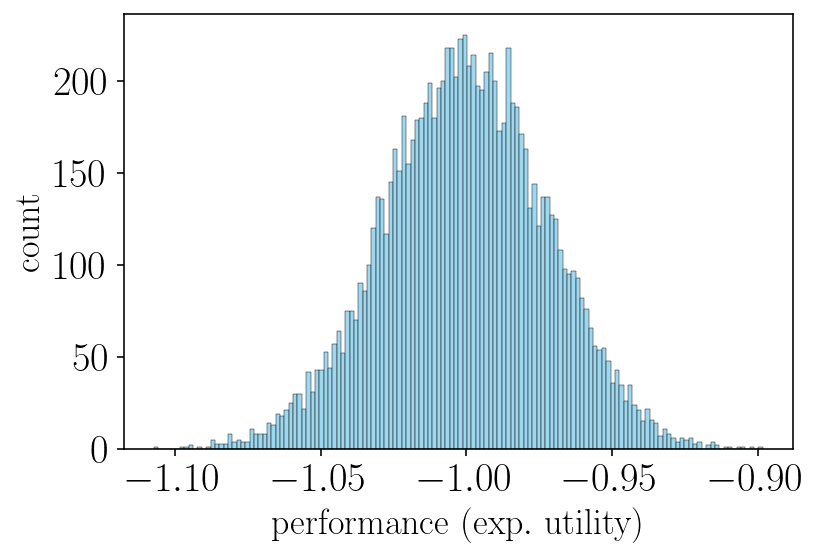

In [36]:
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,4))

sns.histplot(data=perf[0,:], bins = 140, kde=False, color="skyblue",  ax=axs, alpha =0.8)
axs.set_xlabel(r'$\mathrm{performance}\,\,\mathrm{(exp.~utility)}$', fontsize = 18)
axs.set_ylabel(r'$\mathrm{count}$', fontsize = 18)
plt.show()

In [37]:
print(f'LP\'s expected performance (exponential utility, strag_LP:{strag_LP}, strag_vn:{strag_vn}): {perf[0,:].mean():1.5f}')
print(f'LP\'s expected wealth: {wealth[0,:].mean():1.5f}')
print(f'Expected reward: {rew[-1,:].mean():1.5f}')

LP's expected performance (exponential utility, strag_LP:1, strag_vn:1): -1.00028
LP's expected wealth: 1145544.19439
Expected reward: 6003497.45592


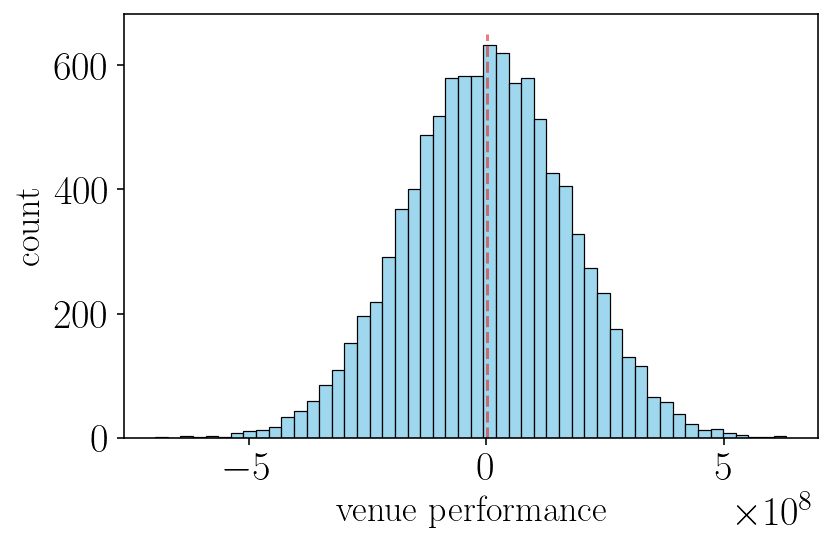

In [38]:
fig, axs = plt.subplots(1, 1, sharex=True, figsize=(6,4))

sns.histplot(data=venue_wealth[0,:], bins = 50, kde=False, color="skyblue",  ax=axs, alpha =0.8)
plt.vlines(x = np.mean(venue_wealth[0,:]), ymin=0,ymax=650, linestyle='--', color='tab:red', alpha =0.6)

axs.set_xlabel(r'$\mathrm{venue~performance}$', fontsize = 18)
axs.set_ylabel(r'$\mathrm{count}$', fontsize = 18)
plt.tight_layout()
plt.savefig(f'figures/hist-venue-perf-{risk_type}.pdf', format="pdf", dpi=dpi)
plt.show()

In [39]:
np.mean(venue_wealth[0,:])

2024044.9690838302

In [40]:
print(f'Venue\'s expected performance (LQ utility): {venue_wealth[0,:].mean():1.5f}')

Venue's expected performance (LQ utility): 2024044.96908


In [41]:
np.exp(-env.gamma*env.P0)

0.9999999999

# LP does not trade

In [11]:
np.random.seed(100)

In [12]:
nsims = 1_000
strag_LP = '0'
strag_vn = '1'

S, Y, Z, X, nu, wealth, perf, rew, venue_wealth = env.simulate_venue(nsims=nsims, strag_LP=strag_LP, strag_vn=strag_vn, verbose = False)

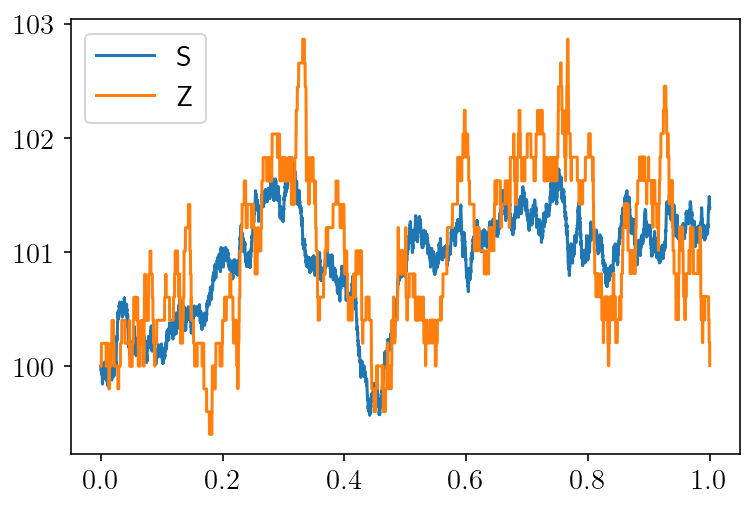

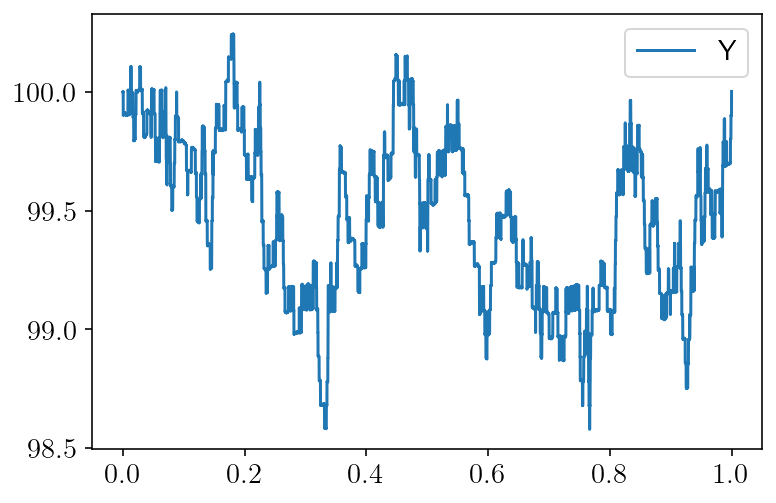

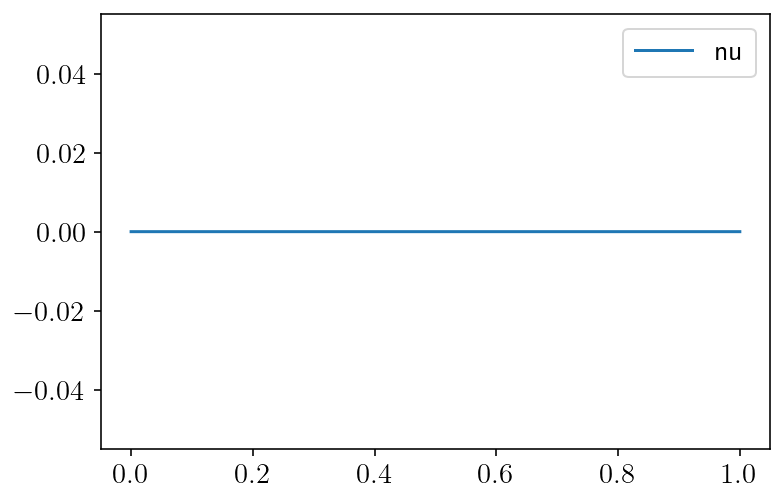

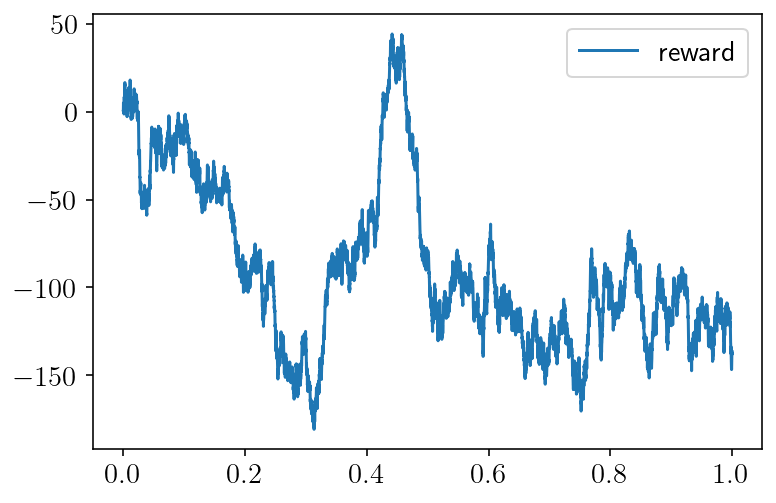

In [13]:
num_sim = 58

plt.plot(env.timesteps, S[:,num_sim], label='S')
plt.plot(env.timesteps, Z[:,num_sim], label='Z')
plt.legend()
plt.show()

plt.plot(env.timesteps, Y[:,num_sim], label='Y')
plt.legend()
plt.show()

#plt.plot(env.timesteps, Z[:,num_sim], label='Z')
#plt.legend()
#plt.show()

#plt.plot(env.timesteps, X[:,num_sim], label='X')
#plt.legend()
#plt.show()

plt.plot(env.timesteps, nu[:,num_sim], label='nu')
plt.legend()
plt.show()


plt.plot(env.timesteps, rew[:,num_sim], label='reward')
plt.legend()
plt.show()

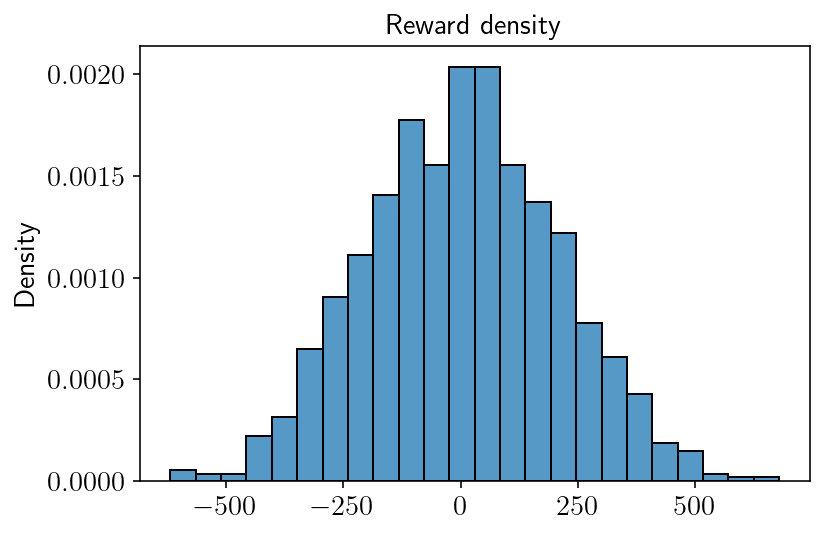

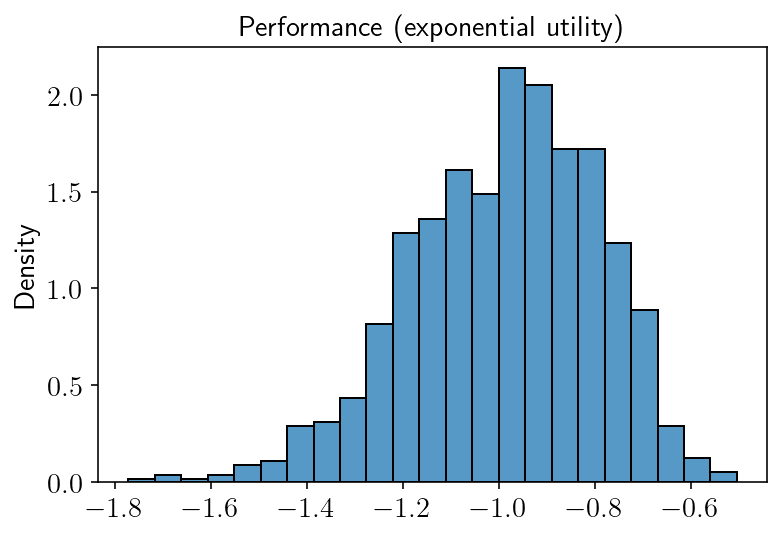

LP's expected performance (exponential utility, strag_LP:0, strag_vn:1): -0.98880
LP's expected wealth: 3.09531
Expected reward: 5.13969


In [14]:
sns.histplot(rew[-1,:], stat='density')
plt.title("Reward density")
plt.show()

sns.histplot(perf[0,:], stat='density')
plt.title("Performance (exponential utility)")
plt.show()

print(f'LP\'s expected performance (exponential utility, strag_LP:{strag_LP}, strag_vn:{strag_vn}): {perf[0,:].mean():1.5f}')
print(f'LP\'s expected wealth: {wealth[0,:].mean():1.5f}')
print(f'Expected reward: {rew[-1,:].mean():1.5f}')

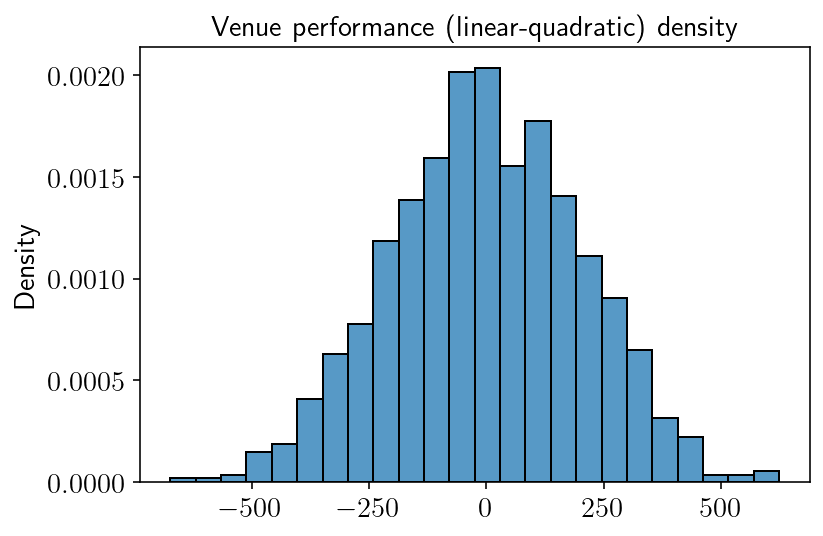

Venue's expected performance (LQ utility): 0.86906


In [15]:
sns.histplot(venue_wealth[0,:], stat='density')
plt.title("Venue performance (linear-quadratic) density")
plt.show()

print(f'Venue\'s expected performance (LQ utility): {venue_wealth[0,:].mean():1.5f}')

# Venue doesn't give reward

In [16]:
np.random.seed(100)

nsims = 1_000
strag_LP = '1'
strag_vn = '0'

S, Y, Z, X, nu, wealth, perf, rew, venue_wealth = env.simulate_venue(nsims=nsims, strag_LP=strag_LP, strag_vn=strag_vn, verbose = False)

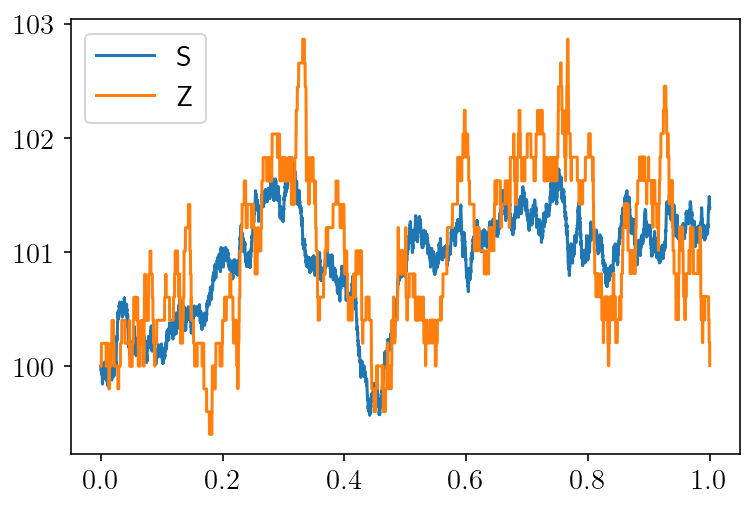

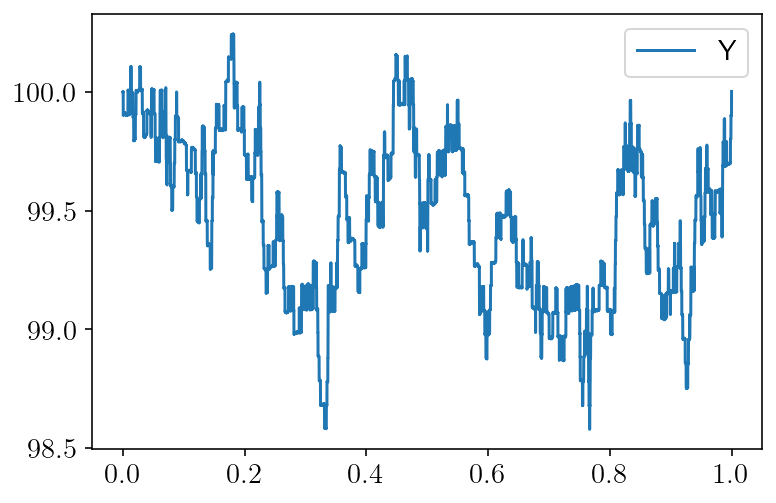

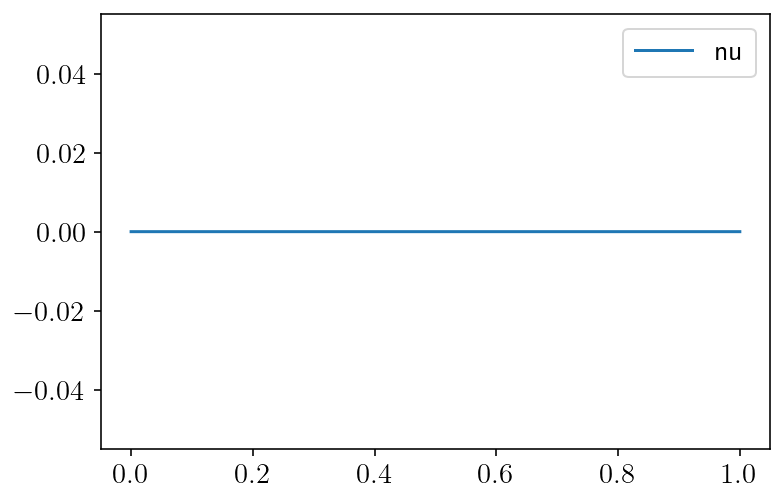

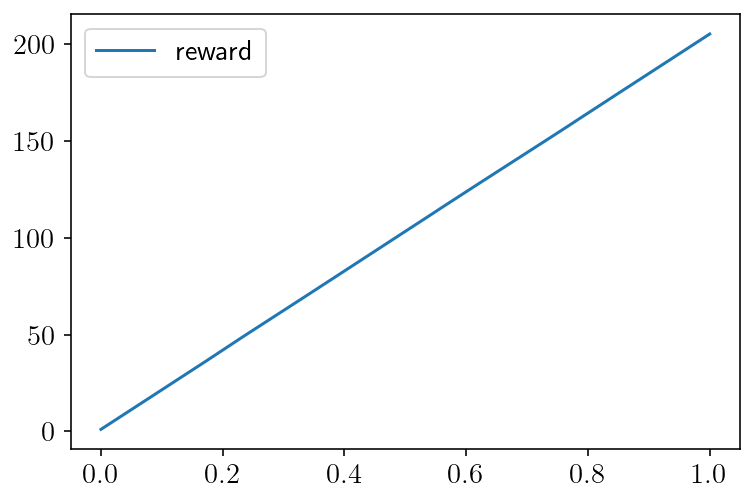

In [17]:
num_sim = 58

plt.plot(env.timesteps, S[:,num_sim], label='S')
plt.plot(env.timesteps, Z[:,num_sim], label='Z')
plt.legend()
plt.show()

plt.plot(env.timesteps, Y[:,num_sim], label='Y')
plt.legend()
plt.show()

#plt.plot(env.timesteps, Z[:,num_sim], label='Z')
#plt.legend()
#plt.show()

#plt.plot(env.timesteps, X[:,num_sim], label='X')
#plt.legend()
#plt.show()

plt.plot(env.timesteps, nu[:,num_sim], label='nu')
plt.legend()
plt.show()


plt.plot(env.timesteps, rew[:,num_sim], label='reward')
plt.legend()
plt.show()

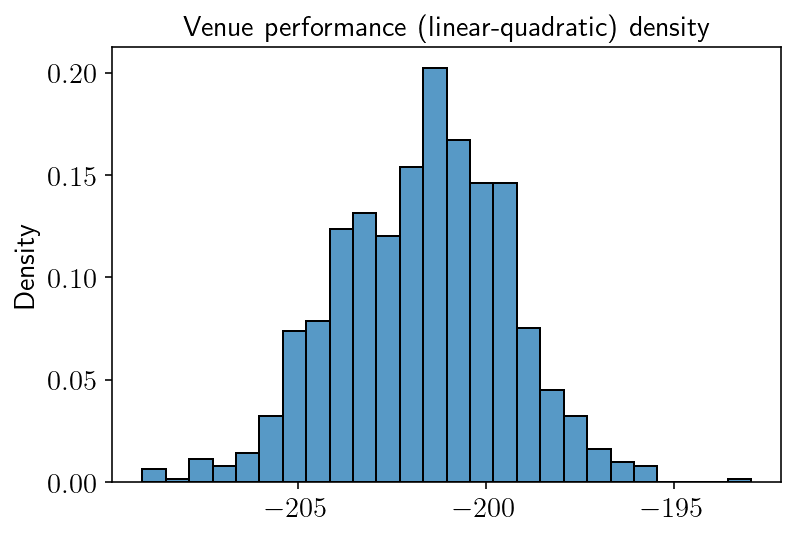

Venue's expected performance (LQ utility): -201.67812


In [18]:
sns.histplot(venue_wealth[0,:], stat='density')
plt.title("Venue performance (linear-quadratic) density")
plt.show()

print(f'Venue\'s expected performance (LQ utility): {venue_wealth[0,:].mean():1.5f}')